In [1]:


from google.colab import files
uploaded = files.upload()


Saving cardio_train.csv to cardio_train.csv


In [3]:


import zipfile
import os

csv_path = None

# Check if a CSV was uploaded directly
direct_csv = next((name for name in uploaded if name.lower().endswith('.csv')), None)

if direct_csv:
    print(f"Direct CSV file detected: {direct_csv}")
    csv_path = direct_csv
else:
    # Try to find and extract a ZIP file
    zip_file = next(
        (name for name in uploaded if name.lower().endswith(".zip")),
        None
    )

    if zip_file:
        with zipfile.ZipFile(zip_file, 'r') as zip_ref:
            zip_ref.extractall("cardio_dataset")
        print("Dataset extracted successfully!")

        # Locate CSV file inside the extracted folder
        for root, dirs, filenames in os.walk("cardio_dataset"):
            for filename in filenames:
                if filename.lower().endswith(".csv"):
                    csv_path = os.path.join(root, filename)
                    break
            if csv_path:
                break
    else:
        print("No CSV or ZIP file found in the uploaded files.")

print("CSV File Path:", csv_path)

Direct CSV file detected: cardio_train.csv
CSV File Path: cardio_train.csv


In [4]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")


All libraries imported successfully!


In [5]:


df = pd.read_csv(csv_path, sep=';')

print("Dataset loaded successfully!")

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


Dataset loaded successfully!

First 5 Records:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0



Dataset Shape:
(70000, 13)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB

Missing Values:
id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc   

Statistical Summary:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000



Cardiovascular Disease Distribution:
cardio
0    35021
1    34979
Name: count, dtype: int64


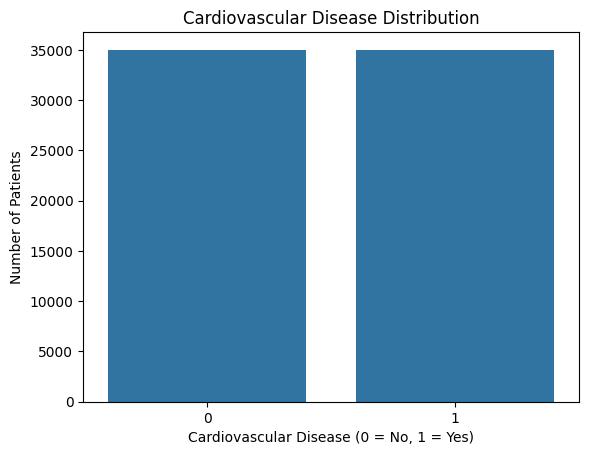

In [6]:

#DATA ANALYSIS

print("Statistical Summary:")
display(df.describe())

print("\nCardiovascular Disease Distribution:")

print(df['cardio'].value_counts())

sns.countplot(data=df, x='cardio')

plt.title("Cardiovascular Disease Distribution")
plt.xlabel("Cardiovascular Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.show()


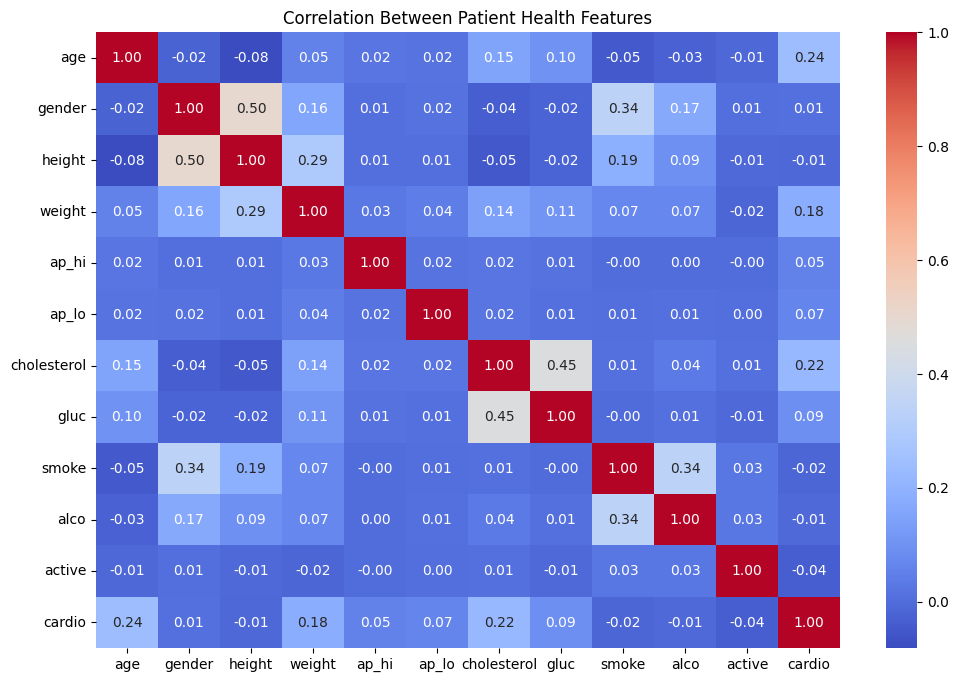

In [7]:

# CORRELATION HEATMAP

plt.figure(figsize=(12, 8))

sns.heatmap(
    df.drop(columns=['id']).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Between Patient Health Features")
plt.show()


In [8]:

#DATA CLEANING

# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove patient ID
df = df.drop(columns=['id'])

# Convert age from days into years
df['age'] = (df['age'] / 365.25).round(1)

# Remove implausible measurements using
# transparent project-level screening rules
valid = (
    df['height'].between(100, 220) &
    df['weight'].between(30, 200) &
    df['ap_hi'].between(60, 250) &
    df['ap_lo'].between(40, 150) &
    (df['ap_hi'] > df['ap_lo'])
)

before = len(df)
df = df.loc[valid].copy()
removed = before - len(df)

print("Records before cleaning:", before)
print("Records removed:", removed)
print("Records after cleaning:", len(df))

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nTarget distribution:")
print(df['cardio'].value_counts())


Records before cleaning: 70000
Records removed: 1366
Records after cleaning: 68634

Missing values:
0

Target distribution:
cardio
0    34680
1    33954
Name: count, dtype: int64


In [9]:

#  FEATURE SELECTION

X = df.drop(columns=['cardio'])

y = df['cardio']

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print("cardio")

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)


Input Features:
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

Target Variable:
cardio

X Shape: (68634, 11)
y Shape: (68634,)


In [10]:

# SPLIT DATASET

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])


Training Records: 54907
Testing Records: 13727


In [11]:

#  MODEL IMPLEMENTATION

models = {
    "Decision Tree": Pipeline([
        ('scaler', StandardScaler()),
        ('model', DecisionTreeClassifier(
            max_depth=10,
            random_state=42
        ))
    ]),

    "Naive Bayes": Pipeline([
        ('scaler', StandardScaler()),
        ('model', GaussianNB())
    ]),

    "KNN": Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(
            n_neighbors=7
        ))
    ]),

    "ANN": Pipeline([
        ('scaler', StandardScaler()),
        ('model', MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation='relu',
            solver='adam',
            max_iter=250,
            early_stopping=True,
            random_state=42
        ))
    ])
}

print("All four classification models created!")


All four classification models created!


In [12]:

# CROSS VALIDATION

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'CV Mean Accuracy': scores.mean(),
        'CV Std': scores.std()
    })

    print("\nModel:", name)
    print("Fold Scores:", scores)
    print("Mean Accuracy:", scores.mean())

cv_df = pd.DataFrame(cv_results)

print("\nCROSS VALIDATION COMPARISON")
display(cv_df)



Model: Decision Tree
Fold Scores: [0.72217669 0.71773577 0.72309037]
Mean Accuracy: 0.7210009438550915

Model: Naive Bayes
Fold Scores: [0.71529257 0.70904819 0.70992241]
Mean Accuracy: 0.7114210597644157

Model: KNN
Fold Scores: [0.70491176 0.70959458 0.70527811]
Mean Accuracy: 0.7065948182026901

Model: ANN
Fold Scores: [0.7346883  0.73177795 0.73369031]
Mean Accuracy: 0.7333855190998713

CROSS VALIDATION COMPARISON


,Model,CV Mean Accuracy,CV Std
0,Decision Tree,0.721001,0.002339
1,Naive Bayes,0.711421,0.002761
2,KNN,0.706595,0.002126
3,ANN,0.733386,0.001208


In [13]:

#  MODEL TRAINING

for name, model in models.items():

    model.fit(X_train, y_train)

    print(name, "trained successfully!")


Decision Tree trained successfully!
Naive Bayes trained successfully!
KNN trained successfully!
ANN trained successfully!


In [14]:

#  PERFORMANCE EVALUATION

results = []

predictions = {}

for name, model in models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    print("\n", name)
    print(classification_report(y_test, y_pred))

results_df = pd.DataFrame(results)

print("\nFINAL MODEL COMPARISON")

display(
    results_df.sort_values(
        by='F1 Score',
        ascending=False
    )
)



 Decision Tree
              precision    recall  f1-score   support

           0       0.69      0.79      0.74      6936
           1       0.75      0.65      0.69      6791

    accuracy                           0.72     13727
   macro avg       0.72      0.72      0.72     13727
weighted avg       0.72      0.72      0.72     13727


 Naive Bayes
              precision    recall  f1-score   support

           0       0.68      0.81      0.74      6936
           1       0.76      0.61      0.67      6791

    accuracy                           0.71     13727
   macro avg       0.72      0.71      0.71     13727
weighted avg       0.72      0.71      0.71     13727


 KNN
              precision    recall  f1-score   support

           0       0.70      0.72      0.71      6936
           1       0.71      0.69      0.70      6791

    accuracy                           0.70     13727
   macro avg       0.70      0.70      0.70     13727
weighted avg       0.70      0.70     

,Model,Accuracy,Precision,Recall,F1 Score
3,ANN,0.730968,0.750323,0.683699,0.715463
2,KNN,0.704524,0.707480,0.686644,0.696906
0,Decision Tree,0.717054,0.747911,0.645708,0.693061
1,Naive Bayes,0.709769,0.758329,0.606685,0.674084


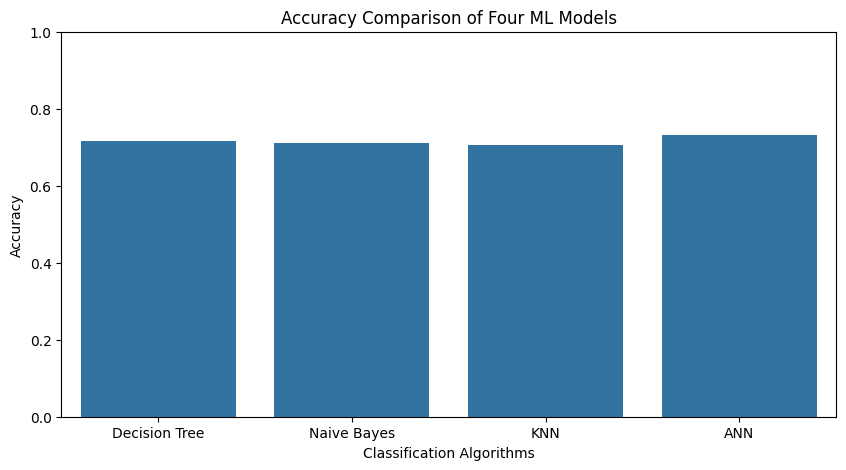

In [15]:

#  MODEL ACCURACY COMPARISON

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title("Accuracy Comparison of Four ML Models")
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.xlabel("Classification Algorithms")

plt.show()


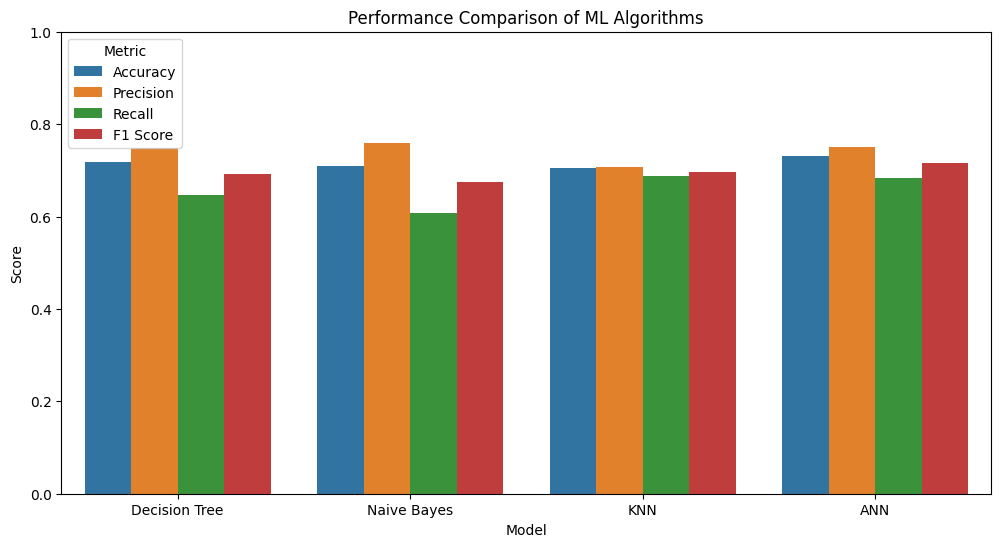

In [16]:

#  PRECISION, RECALL AND F1 COMPARISON

plot_df = results_df.melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title("Performance Comparison of ML Algorithms")
plt.ylim(0, 1)
plt.show()


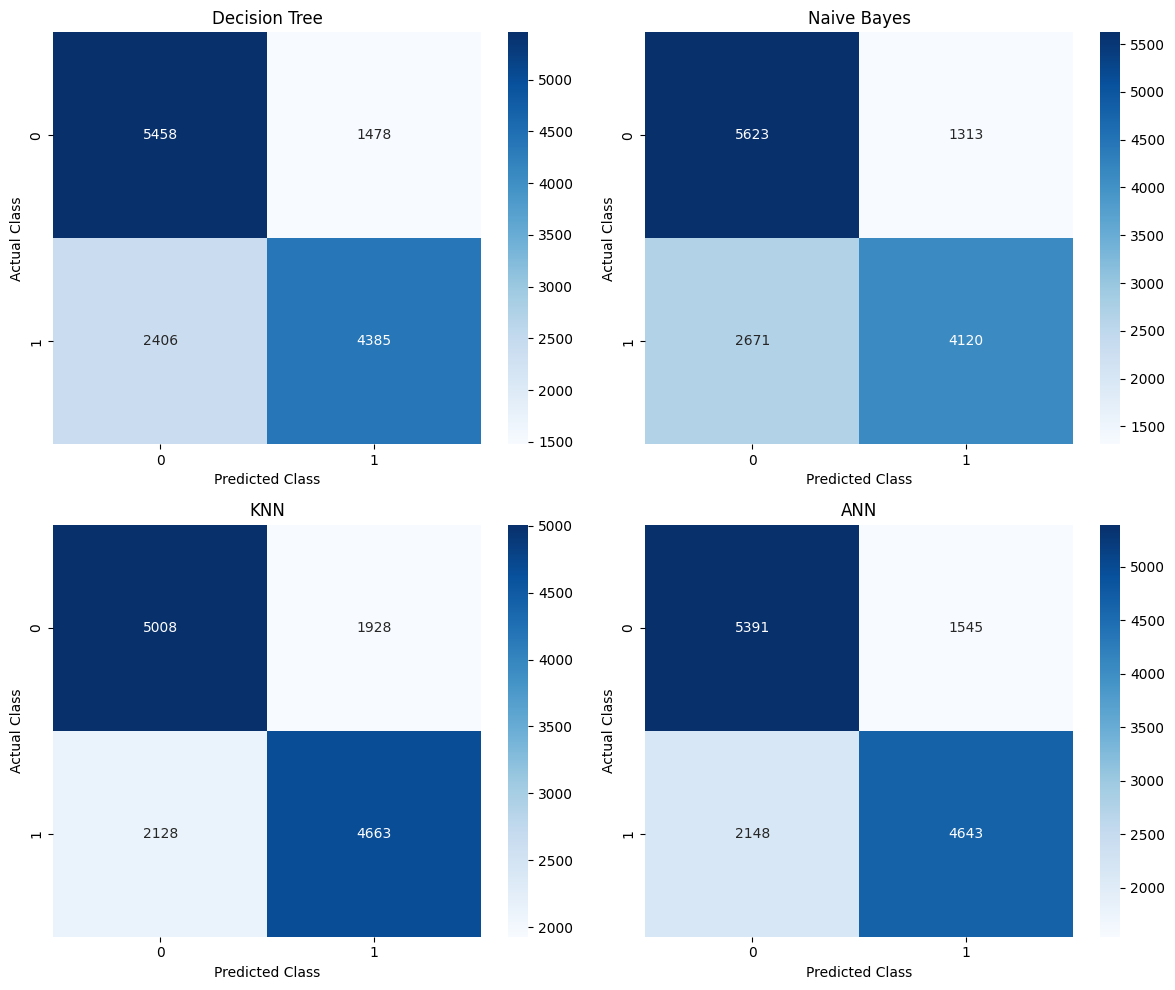

In [17]:

#  CONFUSION MATRIX

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(
    axes.flatten(),
    predictions.items()
):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()


In [18]:

#  FEATURE IMPORTANCE

importance_results = []

# Use a sample to reduce computation time
sample_size = min(5000, len(X_test))

X_sample = X_test.sample(
    n=sample_size,
    random_state=42
)

y_sample = y_test.loc[X_sample.index]

for name, model in models.items():

    importance = permutation_importance(
        model,
        X_sample,
        y_sample,
        n_repeats=5,
        random_state=42,
        scoring='f1',
        n_jobs=-1
    )

    importance_df = pd.DataFrame({
        'Feature': X.columns,
        'Importance': importance.importances_mean
    })

    importance_df['Model'] = name

    importance_results.append(importance_df)

    print("\nFeature Importance:", name)

    display(
        importance_df.sort_values(
            by='Importance',
            ascending=False
        )
    )

all_importance = pd.concat(
    importance_results,
    ignore_index=True
)



Feature Importance: Decision Tree


,Feature,Importance,Model
4,ap_hi,0.133371,Decision Tree
6,cholesterol,0.027717,Decision Tree
0,age,0.013480,Decision Tree
5,ap_lo,0.002051,Decision Tree
2,height,0.001735,Decision Tree
1,gender,0.000928,Decision Tree
8,smoke,-0.000808,Decision Tree
3,weight,-0.001140,Decision Tree
7,gluc,-0.001146,Decision Tree
9,alco,-0.001192,Decision Tree



Feature Importance: Naive Bayes


,Feature,Importance,Model
4,ap_hi,0.077053,Naive Bayes
6,cholesterol,0.026301,Naive Bayes
5,ap_lo,0.023503,Naive Bayes
0,age,0.009908,Naive Bayes
3,weight,0.004744,Naive Bayes
10,active,-0.000451,Naive Bayes
2,height,-0.000461,Naive Bayes
8,smoke,-0.000796,Naive Bayes
9,alco,-0.000973,Naive Bayes
1,gender,-0.001345,Naive Bayes



Feature Importance: KNN


,Feature,Importance,Model
4,ap_hi,0.096589,KNN
6,cholesterol,0.024337,KNN
0,age,0.019247,KNN
5,ap_lo,0.011185,KNN
2,height,0.006368,KNN
3,weight,0.003704,KNN
7,gluc,0.003681,KNN
1,gender,0.003120,KNN
10,active,0.003043,KNN
8,smoke,0.002922,KNN



Feature Importance: ANN


,Feature,Importance,Model
4,ap_hi,0.135367,ANN
6,cholesterol,0.025755,ANN
0,age,0.016067,ANN
3,weight,0.003356,ANN
2,height,0.003302,ANN
7,gluc,0.002818,ANN
5,ap_lo,0.001966,ANN
8,smoke,0.000830,ANN
1,gender,0.000396,ANN
9,alco,-0.000108,ANN


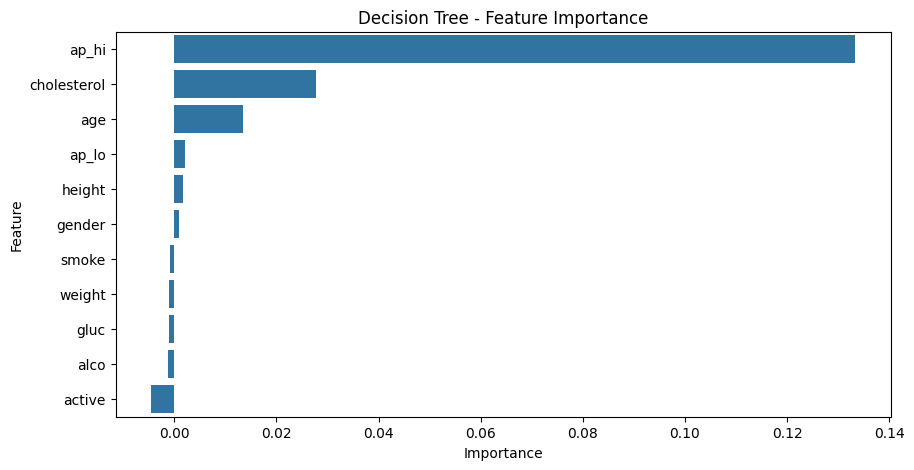

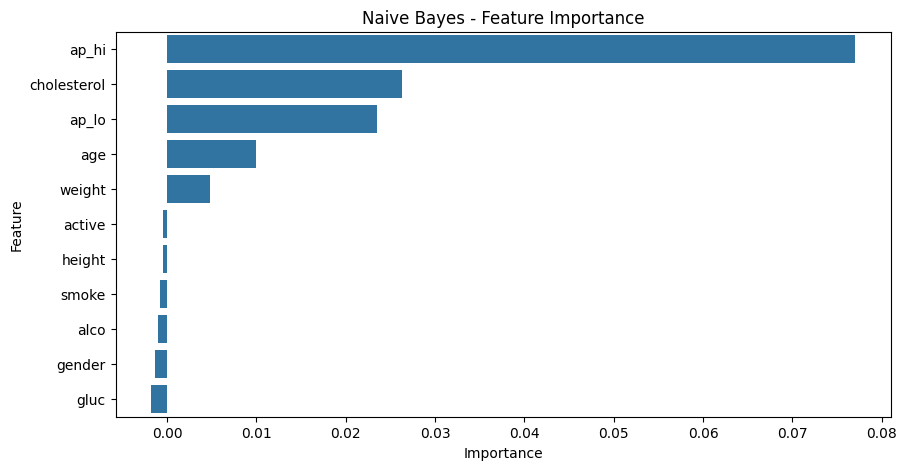

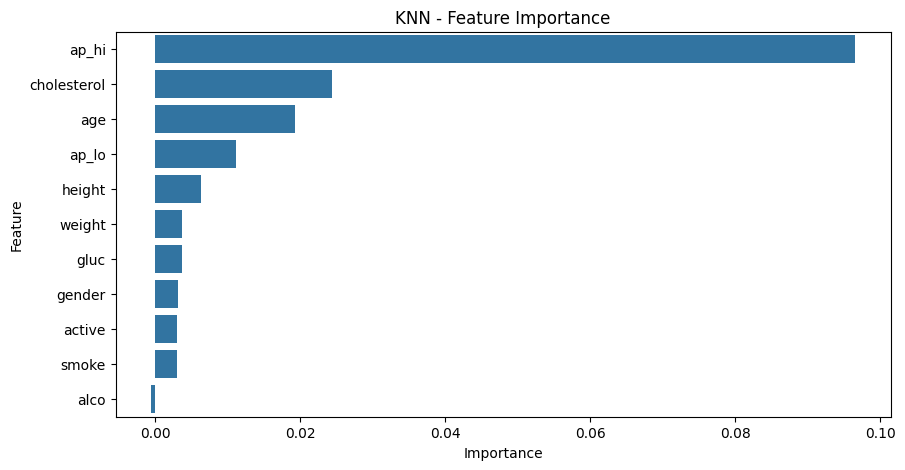

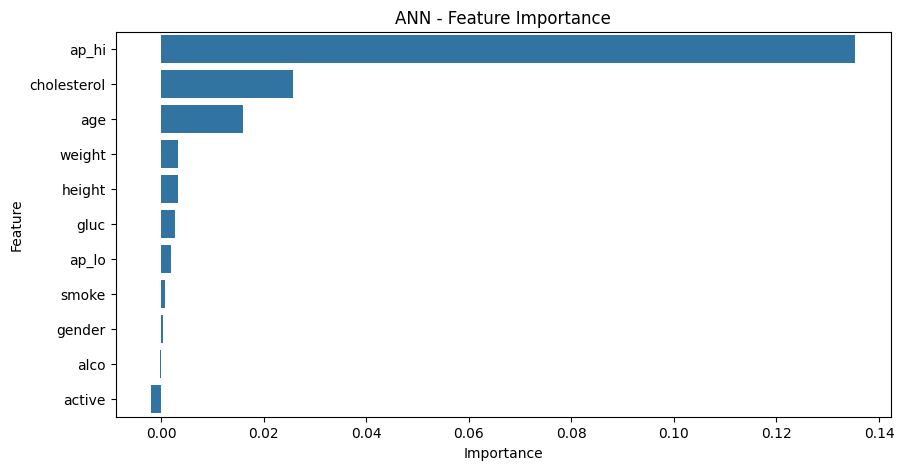

In [19]:

#  VISUALIZE FEATURE IMPORTANCE

for name in models.keys():

    temp = all_importance[
        all_importance['Model'] == name
    ].sort_values(
        by='Importance',
        ascending=False
    )

    plt.figure(figsize=(10, 5))

    sns.barplot(
        data=temp,
        x='Importance',
        y='Feature'
    )

    plt.title(name + " - Feature Importance")
    plt.show()


In [20]:

#  SELECT BEST MODEL

best_result = results_df.sort_values(
    by='F1 Score',
    ascending=False
).iloc[0]

best_model_name = best_result['Model']

best_model = models[best_model_name]

print("BEST PERFORMING MODEL:", best_model_name)

print("\nPerformance:")
print("Accuracy:", best_result['Accuracy'])
print("Precision:", best_result['Precision'])
print("Recall:", best_result['Recall'])
print("F1 Score:", best_result['F1 Score'])

print("\nCross Validation Results:")

display(cv_df)


BEST PERFORMING MODEL: ANN

Performance:
Accuracy: 0.730968164930429
Precision: 0.7503232062055591
Recall: 0.6836990134000883
F1 Score: 0.7154634409430619

Cross Validation Results:


,Model,CV Mean Accuracy,CV Std
0,Decision Tree,0.721001,0.002339
1,Naive Bayes,0.711421,0.002761
2,KNN,0.706595,0.002126
3,ANN,0.733386,0.001208


In [21]:

#  SAMPLE PATIENT PREDICTION

sample_patient = pd.DataFrame([{
    'age': 50,
    'gender': 2,
    'height': 170,
    'weight': 75,
    'ap_hi': 120,
    'ap_lo': 80,
    'cholesterol': 1,
    'gluc': 1,
    'smoke': 0,
    'alco': 0,
    'active': 1
}])

prediction = best_model.predict(sample_patient)

print("Prediction:")

if prediction[0] == 1:
    print("Cardiovascular disease category predicted")
else:
    print("Non-cardiovascular disease category predicted")


Prediction:
Non-cardiovascular disease category predicted


In [22]:

#  SAVE RESULTS

results_df.to_csv(
    'cardiovascular_model_results.csv',
    index=False
)

cv_df.to_csv(
    'cardiovascular_cross_validation.csv',
    index=False
)

print("Results saved successfully!")

from google.colab import files

files.download('cardiovascular_model_results.csv')


Results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:

#  PROJECT SUMMARY

print("=" * 55)
print("CARDIOVASCULAR DISEASE PREDICTION PROJECT")
print("=" * 55)

print("\nDataset Records:", len(df))

print("\nAlgorithms Implemented:")
for name in models.keys():
    print("-", name)

print("\nModel Comparison:")
display(results_df.round(4))

print("\nBest Performing Model:", best_model_name)

print("\nProject Execution Completed Successfully!")


CARDIOVASCULAR DISEASE PREDICTION PROJECT

Dataset Records: 68634

Algorithms Implemented:
- Decision Tree
- Naive Bayes
- KNN
- ANN

Model Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.7171,0.7479,0.6457,0.6931
1,Naive Bayes,0.7098,0.7583,0.6067,0.6741
2,KNN,0.7045,0.7075,0.6866,0.6969
3,ANN,0.7310,0.7503,0.6837,0.7155



Best Performing Model: ANN

Project Execution Completed Successfully!
